In [15]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

root_dir = os.getcwd()
data_folder = os.path.abspath(os.path.join(root_dir, "..", "data", "vaastav_data"))
print(f"Data folder: {data_folder}")


Data folder: /Users/augustustranter/Documents/Programming/Projects/fpl/fpl_2026_27/data/vaastav_data


In [16]:
# Load all GW CSVs. Using 2021-22 onwards because that is when position column was added.
SEASONS = ["2021-22", "2022-23", "2023-24", "2024-25", "2025-26"]

BASE_COLS = [
    "name", "position", "element",
    "round", "was_home", "value",
    "minutes", "total_points",
    "goals_scored", "assists", "clean_sheets", "saves",
    "goals_conceded", "bonus", "bps",
    "creativity", "influence", "threat", "ict_index",
    "yellow_cards", "red_cards",
]
XG_COLS = ["expected_goals", "expected_assists", "expected_goal_involvements", "expected_goals_conceded"]

def load_season(season):
    gws_path = os.path.join(data_folder, season, "gws")
    frames = []
    for gw in range(1, 39):
        path = os.path.join(gws_path, f"gw{gw}.csv")
        if not os.path.exists(path):
            continue
        df = pd.read_csv(path)
        df["season"] = season
        frames.append(df)
    return pd.concat(frames, ignore_index=True) if frames else None

season_order = {s: i for i, s in enumerate(SEASONS)}
all_dfs = []
for season in SEASONS:
    df = load_season(season)
    if df is None:
        print(f"No data for {season}")
        continue
    cols = [c for c in BASE_COLS if c in df.columns]
    cols += [c for c in XG_COLS if c in df.columns]
    cols.append("season")
    all_dfs.append(df[cols])
    print(f"{season}: {len(df):,} rows")


data = pd.concat(all_dfs, ignore_index=True)
for col in XG_COLS:
    if col not in data.columns:
        data[col] = np.nan

print(f"Total: {len(data):,} player-GW rows")
data.head()

2021-22: 25,447 rows
2022-23: 26,505 rows
2023-24: 29,725 rows
2024-25: 27,605 rows
2025-26: 29,757 rows
Total: 139,039 player-GW rows


,name,position,element,round,was_home,value,minutes,total_points,goals_scored,assists,...,influence,threat,ict_index,yellow_cards,red_cards,season,expected_goals,expected_assists,expected_goal_involvements,expected_goals_conceded
0,Eric Bailly,DEF,286,1,True,50,0,0,0,0,...,0.0,0.0,0.0,0,0,2021-22,NaN,NaN,NaN,NaN
1,Keinan Davis,FWD,49,1,False,45,0,0,0,0,...,0.0,0.0,0.0,0,0,2021-22,NaN,NaN,NaN,NaN
2,Ayotomiwa Dele-Bashiru,MID,394,1,True,45,0,0,0,0,...,0.0,0.0,0.0,0,0,2021-22,NaN,NaN,NaN,NaN
3,James Ward-Prowse,MID,341,1,False,65,90,2,0,0,...,21.6,0.0,5.2,0,0,2021-22,NaN,NaN,NaN,NaN
4,Bruno Miguel Borges Fernandes,MID,277,1,True,120,90,20,3,0,...,106.2,59.0,20.1,0,0,2021-22,NaN,NaN,NaN,NaN


count     139039
unique        32
top            0
freq       85532
Name: total_points, dtype: int64


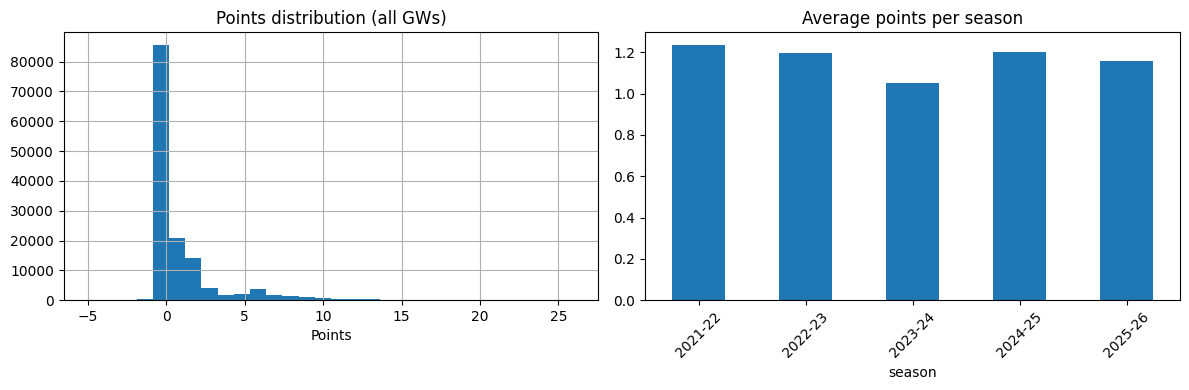

In [17]:
# Quick look at target distribution
print(data["total_points"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data["total_points"].hist(bins=30, ax=axes[0])
axes[0].set_title("Points distribution (all GWs)")
axes[0].set_xlabel("Points")

data.groupby("season")["total_points"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Average points per season")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [18]:
# Build lag features: for each player, shift their stats back 1, 2, 3 GWs.
# This is the history the network uses to predict the current GW.

STAT_COLS = [
    "total_points", "minutes", "goals_scored", "assists",
    "clean_sheets", "saves", "goals_conceded",
    "bonus", "bps", "creativity", "influence", "threat", "ict_index",
]
LAG_STEPS = 3

data["season_idx"] = data["season"].map(season_order)
data = data.sort_values(["element", "season_idx", "round"]).reset_index(drop=True)

for col in STAT_COLS:
    for lag in range(1, LAG_STEPS + 1):
        data[f"{col}_lag{lag}"] = data.groupby("element")[col].shift(lag)

pos_dummies = pd.get_dummies(data["position"], prefix="pos")
data = pd.concat([data, pos_dummies], axis=1)

lag_cols = [f"{c}_lag{lag}" for c in STAT_COLS for lag in range(1, LAG_STEPS + 1)]
pos_cols = list(pos_dummies.columns)
print(f"Lag features: {len(lag_cols)}")
print(f"Position features: {pos_cols}")
data[lag_cols[:6]].head()

Lag features: 39
Position features: ['pos_AM', 'pos_DEF', 'pos_FWD', 'pos_GK', 'pos_GKP', 'pos_MID']


,total_points_lag1,total_points_lag2,total_points_lag3,minutes_lag1,minutes_lag2,minutes_lag3
0,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,NaN,90,NaN,NaN
2,2,1,NaN,90,90,NaN
3,1,2,1,90,90,90
4,0,1,2,0,90,90


In [19]:
# Train on 2021-25, test on 2025-26

FEATURE_COLS = lag_cols + pos_cols + ["was_home", "value"]
TARGET_COL = "total_points"

model_data = data[FEATURE_COLS + [TARGET_COL, "season"]].dropna()
print(f"Rows after dropping NaN: {len(model_data):,}  (dropped {len(data) - len(model_data):,} with no history)")

train_df = model_data[model_data["season"] != "2025-26"]
test_df  = model_data[model_data["season"] == "2025-26"]

X_train = train_df[FEATURE_COLS].values.astype(np.float32)
y_train = train_df[TARGET_COL].values.astype(np.float32)
X_test  = test_df[FEATURE_COLS].values.astype(np.float32)
y_test  = test_df[TARGET_COL].values.astype(np.float32)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")

Rows after dropping NaN: 136,449  (dropped 2,590 with no history)
Train: (106692, 47)  |  Test: (29757, 47)


In [20]:
# Define model

class FPLDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class PointsPredictor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


train_loader = DataLoader(FPLDataset(X_train, y_train), batch_size=512, shuffle=True)
test_loader  = DataLoader(FPLDataset(X_test,  y_test),  batch_size=512)

model = PointsPredictor(input_dim=X_train.shape[1])
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

PointsPredictor(
  (net): Sequential(
    (0): Linear(in_features=47, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 16,513


Epoch  10/60  MSE = 3.9823
Epoch  20/60  MSE = 3.9404
Epoch  30/60  MSE = 3.9251
Epoch  40/60  MSE = 3.8926
Epoch  50/60  MSE = 3.8741
Epoch  60/60  MSE = 3.8574


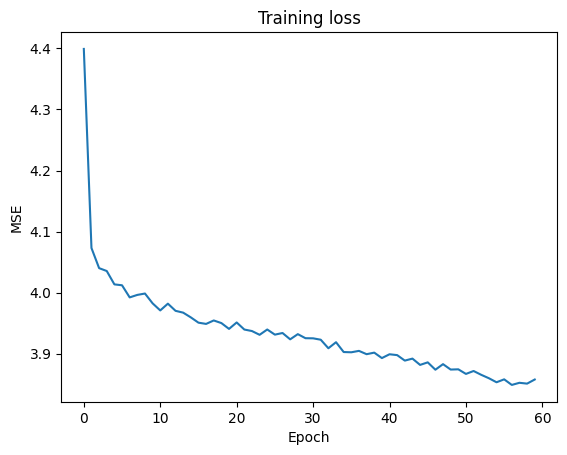

In [21]:
# Train

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()
EPOCHS = 60

train_losses = []
for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(y_batch)
    train_losses.append(epoch_loss / len(y_train))
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS}  MSE = {train_losses[-1]:.4f}")

plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training loss")
plt.show()

MAE — Neural Network:   0.991
MAE — Last GW (lag-1):  1.159
MAE — Rolling 3-GW avg: 1.079


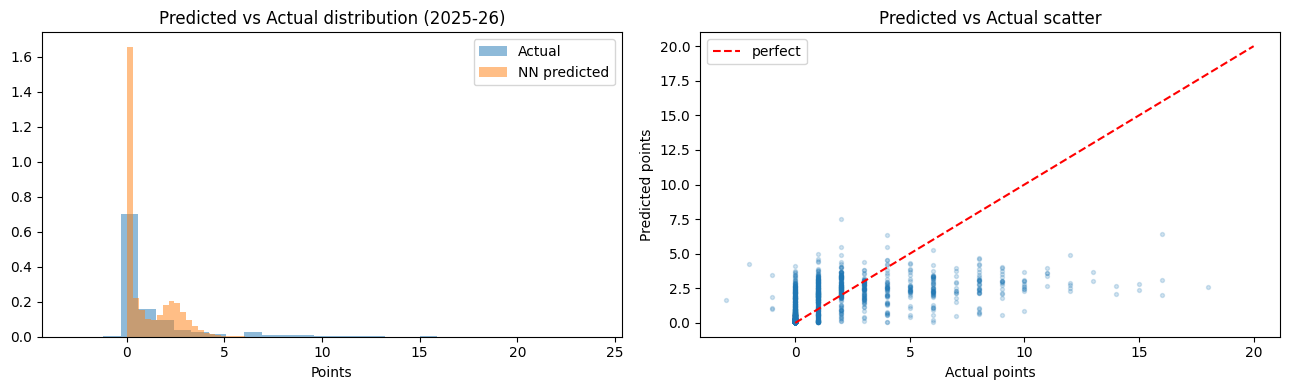

In [22]:
# Evaluate on 2025-26 vs two simple baselines

model.eval()
with torch.no_grad():
    nn_preds = model(torch.tensor(X_test, dtype=torch.float32)).numpy()

baseline_last   = test_df["total_points_lag1"].values
rolling3_preds  = test_df[[f"total_points_lag{i}" for i in range(1, LAG_STEPS + 1)]].mean(axis=1).values

mae_nn       = mean_absolute_error(y_test, nn_preds)
mae_last     = mean_absolute_error(y_test, baseline_last)
mae_rolling3 = mean_absolute_error(y_test, rolling3_preds)

print(f"MAE — Neural Network:   {mae_nn:.3f}")
print(f"MAE — Last GW (lag-1):  {mae_last:.3f}")
print(f"MAE — Rolling 3-GW avg: {mae_rolling3:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(y_test, bins=30, alpha=0.5, label="Actual", density=True)
axes[0].hist(nn_preds, bins=30, alpha=0.5, label="NN predicted", density=True)
axes[0].set_xlabel("Points")
axes[0].set_title("Predicted vs Actual distribution (2025-26)")
axes[0].legend()

idx = np.random.choice(len(y_test), min(2000, len(y_test)), replace=False)
axes[1].scatter(y_test[idx], nn_preds[idx], alpha=0.2, s=8)
axes[1].plot([0, 20], [0, 20], "r--", label="perfect")
axes[1].set_xlabel("Actual points")
axes[1].set_ylabel("Predicted points")
axes[1].set_title("Predicted vs Actual scatter")
axes[1].legend()

plt.tight_layout()
plt.show()